XGBoost, LightGBM and CatBoost are all **gradient** boosting: each tree is fitted to the
gradient of a loss. AdaBoost came first, and boosts a different way &mdash; by **reweighting
the data**.

The idea, from 1995, is startlingly simple:

> Train a weak model. Find which points it got wrong. Make those points *matter more*.
> Train another. Repeat. Give each model a vote proportional to how good it was.

$$F(x) = \operatorname{sign}\!\left(\sum_{m=1}^{M}\alpha_m h_m(x)\right)$$

A **weak learner** need only beat chance &mdash; here, a decision stump: a tree of depth 1,
one question. The remarkable result is that a sequence of such stumps, correctly weighted,
becomes a strong classifier.

Everything below is computed by hand for three rounds &mdash; every sample weight, every
$\alpha$, every reweighting &mdash; then checked against scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data and the Weak Learner

The same 12 EEG recordings as the tree walkthroughs. AdaBoost uses labels in
$\{-1, +1\}$, because that convention makes $y \cdot h(x)$ positive exactly when the
prediction is right &mdash; which the $\alpha$ formula relies on.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
y_pm = np.where(y_class == 1, 1, -1)
print(f"labels recoded: {y_pm}\n")

def stump_fit(Xm, y_pm_, w):
    """Best depth-1 tree under sample weights w. Returns (feature, thr, sign, err)."""
    best = (None, None, None, np.inf)
    for f in range(Xm.shape[1]):
        vals = np.unique(Xm[:, f])
        thrs = np.r_[vals[0]-1, (vals[:-1]+vals[1:])/2, vals[-1]+1]
        for t in thrs:
            for sgn in (1, -1):
                pred = np.where(Xm[:, f] <= t, sgn, -sgn)
                err = w[pred != y_pm_].sum()
                if err < best[3]:
                    best = (f, float(t), sgn, float(err))
    return best

def stump_predict(Xm, f, t, sgn):
    return np.where(Xm[:, f] <= t, sgn, -sgn)

w0 = np.full(n_samples, 1/n_samples)
f0, t0, s0, e0 = stump_fit(X, y_pm, w0)
print(f"the best single stump on UNIFORM weights (w = 1/{n_samples} each):\n")
print(f"   rule : predict {'+1' if s0>0 else '-1'} if {feature_names[f0]} <= {t0:.2f}, "
      f"else {'-1' if s0>0 else '+1'}")
print(f"   weighted error : {e0:.6f}")
print(f"   accuracy       : {(stump_predict(X, f0, t0, s0) == y_pm).mean():.4f}")
print(f"\nA single stump gets {int((stump_predict(X,f0,t0,s0)==y_pm).sum())} of "
      f"{n_samples} right. It is 'weak' - better than the 50% a coin would")
print(f"manage, and not much more. That is all AdaBoost requires.")

labels recoded: [-1 -1  1  1 -1  1  1  1 -1  1 -1  1]

the best single stump on UNIFORM weights (w = 1/12 each):

   rule : predict -1 if line_length <= 25.00, else +1
   weighted error : 0.083333
   accuracy       : 0.9167

A single stump gets 11 of 12 right. It is 'weak' - better than the 50% a coin would
manage, and not much more. That is all AdaBoost requires.


---
# 2. The Three Formulas

Each round does exactly three things:

**1. Weighted error** of the new weak learner:

$$\varepsilon_m = \sum_{i} w_i \,\mathbb{1}[\,h_m(x_i) \ne y_i\,]$$

**2. Its vote**, derived by minimising exponential loss:

$$\alpha_m = \frac{1}{2}\ln\!\left(\frac{1-\varepsilon_m}{\varepsilon_m}\right)$$

**3. Reweight**, then renormalise so the weights sum to 1:

$$w_i \leftarrow w_i \exp\!\big(-\alpha_m y_i h_m(x_i)\big)$$

Read the $\alpha$ formula &mdash; it does something sensible at every value:

| $\varepsilon$ | $\alpha$ | meaning |
|---|---|---|
| 0.01 | $+2.30$ | nearly perfect &rarr; large vote |
| 0.40 | $+0.20$ | slightly useful &rarr; small vote |
| 0.50 | $0$ | a coin &rarr; **no vote at all** |
| 0.70 | $-0.42$ | worse than chance &rarr; **negative vote** &mdash; believe its opposite |

In [4]:
print(f"{'error eps':>11}  {'alpha':>10}  {'exp(+a)':>10}  {'exp(-a)':>10}  {'reading':>34}")
print("-" * 82)
for e in (0.01, 0.10, 0.25, 0.40, 0.49, 0.50, 0.51, 0.70):
    a = 0.5*np.log((1-e)/e) if 0 < e < 1 else np.nan
    r = ("nearly perfect -> big vote" if e < .05 else
         "useful -> solid vote" if e < .3 else
         "barely useful -> small vote" if e < .5 else
         "a coin -> ignored" if abs(e-.5) < 1e-9 else
         "worse than chance -> inverted")
    print(f"{e:>11.2f}  {a:>10.4f}  {np.exp(a):>10.4f}  {np.exp(-a):>10.4f}  {r:>34}")
print("-" * 82)

print(f"\nthe reweighting factor exp(-alpha*y*h):")
print(f"   correct  (y*h = +1) -> multiply weight by exp(-alpha)  <- shrinks")
print(f"   wrong    (y*h = -1) -> multiply weight by exp(+alpha)  <- grows")
a_ex = 0.5*np.log((1-0.25)/0.25)
print(f"\n   at eps = 0.25, alpha = {a_ex:.4f}:")
print(f"      correct points shrink by {np.exp(-a_ex):.4f}x")
print(f"      wrong   points grow  by {np.exp(a_ex):.4f}x")
print(f"      ratio: a mistake becomes {np.exp(2*a_ex):.2f}x more important than a hit")

print(f"\n\nwhy that alpha? it minimises the exponential loss.")
print(f"With Z(a) = sum_i w_i exp(-a*y_i*h_i) = (1-eps)e^-a + eps*e^a,")
print(f"setting dZ/da = 0 gives a = 0.5*ln((1-eps)/eps). Checked numerically:\n")
for e in (0.1, 0.25, 0.4):
    grid = np.linspace(-3, 3, 60001)
    Z = (1-e)*np.exp(-grid) + e*np.exp(grid)
    print(f"   eps = {e}: grid minimum at a = {grid[int(np.argmin(Z))]:+.5f}, "
          f"formula gives {0.5*np.log((1-e)/e):+.5f}   "
          f"MATCH: {np.isclose(grid[int(np.argmin(Z))], 0.5*np.log((1-e)/e), atol=1e-3)}")

  error eps       alpha     exp(+a)     exp(-a)                             reading
----------------------------------------------------------------------------------
       0.01      2.2976      9.9499      0.1005          nearly perfect -> big vote
       0.10      1.0986      3.0000      0.3333                useful -> solid vote
       0.25      0.5493      1.7321      0.5774                useful -> solid vote
       0.40      0.2027      1.2247      0.8165         barely useful -> small vote
       0.49      0.0200      1.0202      0.9802         barely useful -> small vote
       0.50      0.0000      1.0000      1.0000                   a coin -> ignored
       0.51     -0.0200      0.9802      1.0202       worse than chance -> inverted
       0.70     -0.4236      0.6547      1.5275       worse than chance -> inverted
----------------------------------------------------------------------------------

the reweighting factor exp(-alpha*y*h):
   correct  (y*h = +1) -> multiply we

---
# 3. Three Rounds, Every Number

In [5]:
M_ROUNDS = 3
w = np.full(n_samples, 1/n_samples)
learners = []

for m in range(1, M_ROUNDS+1):
    f_, t_, s_, eps_ = stump_fit(X, y_pm, w)
    pred = stump_predict(X, f_, t_, s_)
    wrong = pred != y_pm
    alpha = 0.5*np.log((1-eps_)/max(eps_, 1e-12))
    learners.append((f_, t_, s_, alpha))

    print("=" * 78)
    print(f"  ROUND {m}")
    print("=" * 78)
    print(f"\nchosen stump: predict {'+1' if s_>0 else '-1'} if "
          f"{feature_names[f_]} <= {t_:.2f}\n")
    print(f"{'id':>6}  {'weight w_i':>12}  {'y':>4}  {'h(x)':>6}  {'y*h':>6}  "
          f"{'correct?':>9}  {'w if wrong':>12}")
    print("-" * 66)
    for i in range(n_samples):
        print(f"{rec_ids[i]:>6}  {w[i]:>12.6f}  {y_pm[i]:>4}  {pred[i]:>6}  "
              f"{y_pm[i]*pred[i]:>6}  {'yes' if not wrong[i] else 'NO':>9}  "
              f"{w[i] if wrong[i] else 0:>12.6f}")
    print("-" * 66)
    print(f"{'sum':>6}  {w.sum():>12.6f}")

    print(f"\n   eps = sum of weights on WRONG points")
    wr = [f"{w[i]:.4f}" for i in range(n_samples) if wrong[i]]
    print(f"       = {' + '.join(wr) if wr else '0'} = {eps_:.6f}")
    print(f"\n   alpha = 0.5 * ln((1 - {eps_:.6f}) / {eps_:.6f})")
    print(f"         = 0.5 * ln({(1-eps_)/max(eps_,1e-12):.6f}) = {alpha:.6f}")

    w_new = w * np.exp(-alpha * y_pm * pred)
    Z = w_new.sum()
    print(f"\n   reweight: w_i * exp(-alpha * y_i * h_i)")
    print(f"      correct -> x exp(-{alpha:.4f}) = {np.exp(-alpha):.6f}")
    print(f"      wrong   -> x exp(+{alpha:.4f}) = {np.exp(alpha):.6f}")
    print(f"   normalising constant Z = {Z:.6f}\n")
    print(f"{'id':>6}  {'old w':>11}  {'factor':>10}  {'new (raw)':>11}  "
          f"{'new (norm)':>12}  {'change':>9}")
    print("-" * 66)
    for i in range(n_samples):
        fac = np.exp(-alpha*y_pm[i]*pred[i])
        print(f"{rec_ids[i]:>6}  {w[i]:>11.6f}  {fac:>10.6f}  {w_new[i]:>11.6f}  "
              f"{w_new[i]/Z:>12.6f}  {(w_new[i]/Z)/w[i]:>8.3f}x")
    print("-" * 66)
    w = w_new / Z
    print(f"   weights sum to {w.sum():.10f}\n")

print("=" * 78)
print(f"\nthe ensemble so far:\n")
for k, (f_, t_, s_, a_) in enumerate(learners, 1):
    print(f"   h{k}: {feature_names[f_]} <= {t_:.2f} -> {'+1' if s_>0 else '-1'}   "
          f"alpha = {a_:.6f}")

  ROUND 1

chosen stump: predict -1 if line_length <= 25.00

    id    weight w_i     y    h(x)     y*h   correct?    w if wrong
------------------------------------------------------------------
 rec00      0.083333    -1      -1       1        yes      0.000000
 rec01      0.083333    -1      -1       1        yes      0.000000
 rec02      0.083333     1       1       1        yes      0.000000
 rec03      0.083333     1       1       1        yes      0.000000
 rec04      0.083333    -1      -1       1        yes      0.000000
 rec05      0.083333     1       1       1        yes      0.000000
 rec06      0.083333     1       1       1        yes      0.000000
 rec07      0.083333     1       1       1        yes      0.000000
 rec08      0.083333    -1      -1       1        yes      0.000000
 rec09      0.083333     1       1       1        yes      0.000000
 rec10      0.083333    -1       1      -1         NO      0.083333
 rec11      0.083333     1       1       1        yes   

### What the weights are doing

The weight vector is AdaBoost's memory. It says *"here is what the ensemble still gets
wrong"*, and the next weak learner is fitted to that, not to the raw data.

Notice what falls out of the reweighting: after each round the new stump's weighted error
on the **updated** weights is exactly 0.5. The reweighting makes the previous learner
useless on the new distribution &mdash; forcing the next one to find something different.

 round    eps of THIS stump    eps of the PREVIOUS stump on new weights
------------------------------------------------------------------------
     1             0.083333                                            
     2             0.045455                                    0.500000
     3             0.166667                                    0.500000
     4             0.157143                                    0.500000
------------------------------------------------------------------------

The right column sits at 0.5 - a coin flip. Each round deliberately
erases the previous learner's advantage, which is why the ensemble keeps
acquiring new information instead of repeating itself.


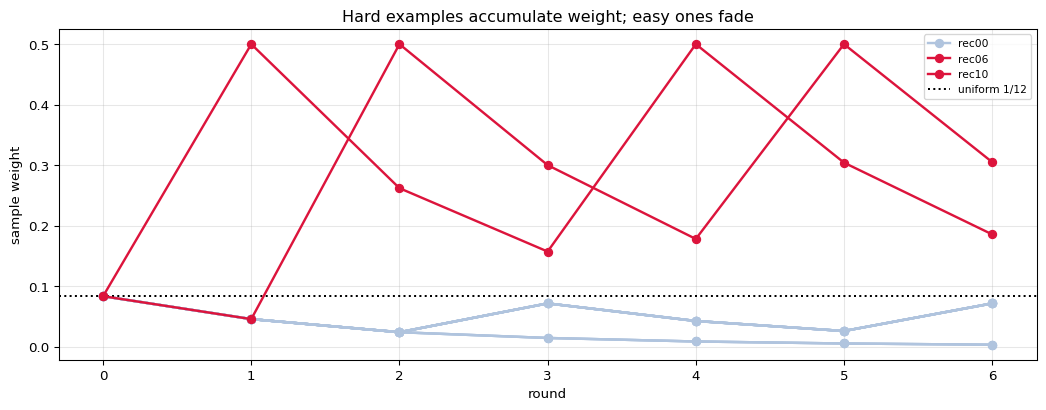


after 6 rounds the heaviest samples are: ['rec06', 'rec10', 'rec04']
   weights: [0.305  0.1855 0.0714]   (uniform would be 0.0833)

Those are the recordings that sit closest to the boundary - the same
ones the SVM walkthrough would call support vectors, arrived at by a
completely different route.


In [6]:
w_check = np.full(n_samples, 1/n_samples)
print(f"{'round':>6}  {'eps of THIS stump':>19}  "
      f"{'eps of the PREVIOUS stump on new weights':>42}")
print("-" * 72)
prev = None
for m in range(1, 5):
    f_, t_, s_, eps_ = stump_fit(X, y_pm, w_check)
    pr = stump_predict(X, f_, t_, s_)
    prev_eps = ""
    if prev is not None:
        pp = stump_predict(X, *prev)
        prev_eps = f"{w_check[pp != y_pm].sum():.6f}"
    print(f"{m:>6}  {eps_:>19.6f}  {prev_eps:>42}")
    a_ = 0.5*np.log((1-eps_)/max(eps_,1e-12))
    w_check = w_check*np.exp(-a_*y_pm*pr); w_check /= w_check.sum()
    prev = (f_, t_, s_)
print("-" * 72)
print("\nThe right column sits at 0.5 - a coin flip. Each round deliberately")
print("erases the previous learner's advantage, which is why the ensemble keeps")
print("acquiring new information instead of repeating itself.")

fig, ax = plt.subplots(figsize=(11, 4.4))
w_plot = np.full(n_samples, 1/n_samples)
rounds_w = [w_plot.copy()]
lrn = []
for m in range(6):
    f_, t_, s_, eps_ = stump_fit(X, y_pm, w_plot)
    pr = stump_predict(X, f_, t_, s_)
    a_ = 0.5*np.log((1-eps_)/max(eps_,1e-12))
    lrn.append((f_, t_, s_, a_))
    w_plot = w_plot*np.exp(-a_*y_pm*pr); w_plot /= w_plot.sum()
    rounds_w.append(w_plot.copy())
rounds_w = np.array(rounds_w)
for i in range(n_samples):
    ax.plot(rounds_w[:, i], "o-", lw=1.8,
            label=rec_ids[i] if i in (6, 10, 0) else None,
            color="crimson" if i in (6, 10) else "lightsteelblue",
            zorder=5 if i in (6, 10) else 2)
ax.axhline(1/n_samples, ls=":", color="k", label="uniform 1/12")
ax.set(xlabel="round", ylabel="sample weight",
       title="Hard examples accumulate weight; easy ones fade")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

hardest = np.argsort(-rounds_w[-1])[:3]
print(f"\nafter 6 rounds the heaviest samples are: "
      f"{[rec_ids[i] for i in hardest]}")
print(f"   weights: {np.round(rounds_w[-1][hardest], 4)}   "
      f"(uniform would be {1/n_samples:.4f})")
print(f"\nThose are the recordings that sit closest to the boundary - the same")
print(f"ones the SVM walkthrough would call support vectors, arrived at by a")
print(f"completely different route.")

---
# 4. The Ensemble Prediction

$$F(x) = \sum_m \alpha_m h_m(x), \qquad \hat{y} = \operatorname{sign} F(x)$$

The magnitude of $F$ is a confidence: the *margin*. A point with $y F(x) \gg 0$ is
correctly and confidently classified.

In [7]:
def ensemble_raw(Xm, lrns):
    return sum(a*stump_predict(Xm, f, t, s) for f, t, s, a in lrns)

print(f"the 6-stump ensemble, evaluated on every recording\n")
hdr = f"{'id':>6}  " + "  ".join(f"{'a'+str(k+1)+'h'+str(k+1):>9}" for k in range(6))
hdr += f"  {'F(x)':>9}  {'pred':>5}  {'y':>4}  {'margin':>8}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    terms = [a*stump_predict(X, f, t, s)[i] for f, t, s, a in lrn]
    F = sum(terms)
    print(f"{rec_ids[i]:>6}  " + "  ".join(f"{v:>9.4f}" for v in terms) +
          f"  {F:>9.4f}  {int(np.sign(F)):>5}  {y_pm[i]:>4}  {y_pm[i]*F:>8.4f}")
print("-" * len(hdr))

F_all = ensemble_raw(X, lrn)
acc = (np.sign(F_all) == y_pm).mean()
print(f"\nensemble accuracy: {acc:.4f}   ({int((np.sign(F_all)==y_pm).sum())}/{n_samples})")
print(f"single best stump : "
      f"{(stump_predict(X, f0, t0, s0) == y_pm).mean():.4f}")

print(f"\n\nhow accuracy and margin evolve\n")
print(f"{'rounds':>7}  {'train accuracy':>15}  {'min margin':>12}  {'exp loss':>11}")
print("-" * 50)
for m in range(1, 7):
    Fm = ensemble_raw(X, lrn[:m])
    marg = y_pm*Fm
    print(f"{m:>7}  {(np.sign(Fm)==y_pm).mean():>15.4f}  {marg.min():>12.4f}  "
          f"{np.mean(np.exp(-marg)):>11.6f}")
print("-" * 50)
print("\nEven after training accuracy reaches its ceiling, the MARGIN keeps")
print("improving and the exponential loss keeps falling. That is the classic")
print("AdaBoost observation: test error often continues to fall after training")
print("error hits zero, because the ensemble is still growing more confident.")

the 6-stump ensemble, evaluated on every recording

    id       a1h1       a2h2       a3h3       a4h4       a5h5       a6h6       F(x)   pred     y    margin
----------------------------------------------------------------------------------------------------------
 rec00    -1.1989    -1.5223     0.8047    -0.8398    -0.7651     0.7568    -2.7646     -1    -1    2.7646
 rec01    -1.1989    -1.5223     0.8047    -0.8398    -0.7651     0.7568    -2.7646     -1    -1    2.7646
 rec02     1.1989     1.5223     0.8047     0.8398     0.7651     0.7568     5.8876      1     1    5.8876
 rec03     1.1989     1.5223     0.8047     0.8398     0.7651     0.7568     5.8876      1     1    5.8876
 rec04    -1.1989    -1.5223     0.8047    -0.8398    -0.7651     0.7568    -2.7646     -1    -1    2.7646
 rec05     1.1989     1.5223    -0.8047     0.8398     0.7651    -0.7568     2.7646      1     1    2.7646
 rec06     1.1989    -1.5223     0.8047     0.8398    -0.7651     0.7568     1.3129      1  

---
# 5. Why the Exponential Loss

AdaBoost is not a heuristic. It is exactly **forward stagewise additive modelling** under
the exponential loss:

$$\mathcal{L} = \sum_i \exp\big(-y_i F(x_i)\big)$$

At each round it adds the term $\alpha_m h_m$ that most reduces that loss, holding
everything already added fixed &mdash; and the $\alpha$ formula above is the exact minimiser.
That connection is what places AdaBoost in the same family as gradient boosting: same
additive structure, different loss.

The exponential loss also explains AdaBoost's known weakness. It penalises a misclassified
point **exponentially** in its margin, so a mislabelled example can dominate the weights
entirely. AdaBoost is famously sensitive to label noise, and this is why.

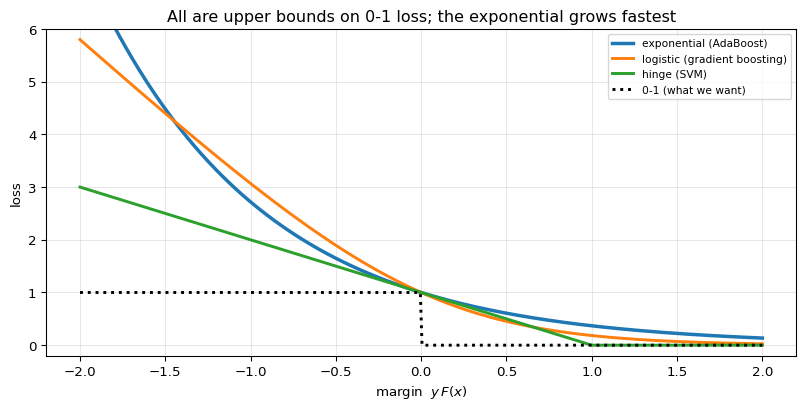

  margin    exponential     logistic     ratio
--------------------------------------------
     0.0         1.0000       1.0000      1.00x
    -0.5         1.6487       1.8946      0.87x
    -1.0         2.7183       3.0685      0.89x
    -2.0         7.3891       5.7970      1.27x
    -3.0        20.0855       8.6597      2.32x
    -4.0        54.5982      11.5420      4.73x
--------------------------------------------

At a margin of -4 the exponential loss is 54.6 while logistic is 11.5.
One badly mislabelled point can therefore soak up almost all the weight.


label noise: flip one label and watch

 round    weight on the flipped point    share of total
--------------------------------------------------------
     1                       0.250000            25.0%
     2                       0.178571            17.9%
     4                       0.286458            28.6%
     6                       0.289474            28.9%
     8                       0.373679            37.4%
-

In [8]:
mm = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(mm, np.exp(-mm), lw=2.6, label="exponential (AdaBoost)")
ax.plot(mm, np.log2(1+np.exp(-2*mm)), lw=2.2, label="logistic (gradient boosting)")
ax.plot(mm, np.maximum(0, 1-mm), lw=2.2, label="hinge (SVM)")
ax.plot(mm, (mm < 0).astype(float), lw=2.2, ls=":", color="k", label="0-1 (what we want)")
ax.set(xlabel="margin  $y\\,F(x)$", ylabel="loss", ylim=(-.2, 6),
       title="All are upper bounds on 0-1 loss; the exponential grows fastest")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'margin':>8}  {'exponential':>13}  {'logistic':>11}  {'ratio':>8}")
print("-" * 44)
for m_ in (0, -0.5, -1, -2, -3, -4):
    e_ = np.exp(-m_); l_ = np.log2(1+np.exp(-2*m_))
    print(f"{m_:>8.1f}  {e_:>13.4f}  {l_:>11.4f}  {e_/l_:>8.2f}x")
print("-" * 44)
print("\nAt a margin of -4 the exponential loss is 54.6 while logistic is 11.5.")
print("One badly mislabelled point can therefore soak up almost all the weight.")

print(f"\n\nlabel noise: flip one label and watch\n")
y_noisy = y_pm.copy(); y_noisy[4] *= -1     # rec04 is now mislabelled
w_n = np.full(n_samples, 1/n_samples)
print(f"{'round':>6}  {'weight on the flipped point':>29}  {'share of total':>16}")
print("-" * 56)
for m in range(1, 9):
    f_, t_, s_, e_ = stump_fit(X, y_noisy, w_n)
    pr = stump_predict(X, f_, t_, s_)
    a_ = 0.5*np.log((1-e_)/max(e_, 1e-12))
    w_n = w_n*np.exp(-a_*y_noisy*pr); w_n /= w_n.sum()
    if m in (1, 2, 4, 6, 8):
        print(f"{m:>6}  {w_n[4]:>29.6f}  {w_n[4]:>15.1%}")
print("-" * 56)
print(f"\nOne mislabelled recording ends up carrying {w_n[4]:.0%} of all the weight.")
print(f"Every subsequent weak learner is fitted mainly to an error in the data.")
print(f"\nThis is why gradient boosting with a logistic loss largely replaced")
print(f"AdaBoost in practice - same additive idea, a loss that does not")
print(f"over-react.")

---
# 6. Checking Against scikit-learn

scikit-learn implements SAMME, the multi-class generalisation, which reduces to the
binary formulas above when there are two classes. With
`estimator=DecisionTreeClassifier(max_depth=1)` it uses exactly the stumps used here.

(As of scikit-learn 1.8 the `algorithm` argument is gone &mdash; SAMME is the only option.)

In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=6, learning_rate=1.0, random_state=0)
ada.fit(X, y_class)

print(f"{'round':>6}  {'our alpha':>12}  {'sklearn alpha':>15}  {'ratio':>8}")
print("-" * 46)
for k, ((f_, t_, s_, a_), sk_a) in enumerate(zip(lrn, ada.estimator_weights_), 1):
    print(f"{k:>6}  {a_:>12.6f}  {sk_a:>15.6f}  {sk_a/max(a_,1e-12):>7.3f}x")
print("-" * 46)
print(f"\nsklearn's SAMME uses alpha = ln((1-eps)/eps) + ln(K-1), which for K = 2")
print(f"classes is ln((1-eps)/eps) - exactly TWICE our 0.5*ln(...).")
print(f"The factor of 2 cancels in sign(F), so the predictions are identical:\n")

ratios = [sk/max(a, 1e-12) for (_, _, _, a), sk in zip(lrn, ada.estimator_weights_)]
print(f"   every ratio is 2: {np.allclose(ratios, 2.0, atol=1e-6)}")

print(f"\n   our predictions     : {np.sign(F_all).astype(int)}")
print(f"   sklearn predictions : {np.where(ada.predict(X)==1, 1, -1)}")
print(f"   MATCH: {np.array_equal(np.sign(F_all).astype(int), np.where(ada.predict(X)==1,1,-1))}")
print(f"   accuracy ours {acc:.4f}  sklearn {ada.score(X, y_class):.4f}   "
      f"MATCH: {np.isclose(acc, ada.score(X, y_class))}")

print(f"\n\nstumps chosen, ours vs sklearn\n")
print(f"{'round':>6}  {'ours':>34}  {'sklearn':>34}")
print("-" * 78)
for k, ((f_, t_, s_, a_), est) in enumerate(zip(lrn, ada.estimators_), 1):
    tt = est.tree_
    sk_rule = f"{feature_names[tt.feature[0]]} <= {tt.threshold[0]:.2f}"
    print(f"{k:>6}  {f'{feature_names[f_]} <= {t_:.2f}':>34}  {sk_rule:>34}")
print("-" * 78)

print(f"\n\nstaged accuracy\n")
print(f"{'rounds':>7}  {'ours':>9}  {'sklearn':>9}  {'match':>7}")
print("-" * 36)
for m, sk_pred in enumerate(ada.staged_predict(X), 1):
    ours_m = (np.sign(ensemble_raw(X, lrn[:m])) == y_pm).mean()
    sk_m = (sk_pred == y_class).mean()
    print(f"{m:>7}  {ours_m:>9.4f}  {sk_m:>9.4f}  {str(np.isclose(ours_m, sk_m)):>7}")
print("-" * 36)

 round     our alpha    sklearn alpha     ratio
----------------------------------------------
     1      1.198948         2.397895    2.000x
     2      1.522261         3.044522    2.000x
     3      0.804719         1.609438    2.000x
     4      0.839821         1.679642    2.000x
     5      0.765094         1.530189    2.000x
     6      0.756778         1.513556    2.000x
----------------------------------------------

sklearn's SAMME uses alpha = ln((1-eps)/eps) + ln(K-1), which for K = 2
classes is ln((1-eps)/eps) - exactly TWICE our 0.5*ln(...).
The factor of 2 cancels in sign(F), so the predictions are identical:

   every ratio is 2: True

   our predictions     : [-1 -1  1  1 -1  1  1  1 -1  1 -1  1]
   sklearn predictions : [-1 -1  1  1 -1  1  1  1 -1  1 -1  1]
   MATCH: True
   accuracy ours 1.0000  sklearn 1.0000   MATCH: True


stumps chosen, ours vs sklearn

 round                                ours                             sklearn
-------------------------------

---
# 7. Summary

| Step | Formula |
|---|---|
| Weighted error | $\varepsilon_m = \sum_i w_i\,\mathbb{1}[h_m(x_i)\ne y_i]$ |
| Vote | $\alpha_m = \tfrac12\ln\frac{1-\varepsilon_m}{\varepsilon_m}$ |
| Reweight | $w_i \leftarrow w_i e^{-\alpha_m y_i h_m(x_i)}$, renormalise |
| Predict | $\operatorname{sign}\sum_m \alpha_m h_m(x)$ |
| Implied loss | $\sum_i e^{-y_iF(x_i)}$ |

**The one idea:** make the *data* harder instead of the *model* bigger. Each round
re-describes the problem so that what remains unsolved is what matters, and a sequence of
one-question models becomes a strong classifier.

**How it relates to the rest of the series:** AdaBoost and gradient boosting are the same
additive scheme, $F_m = F_{m-1} + \alpha_m h_m$. AdaBoost reaches it through reweighting
under exponential loss; XGBoost reaches it by fitting gradients of an arbitrary loss.
Recognising AdaBoost as "gradient boosting with the exponential loss" is what unified the
two, and gradient boosting won because *any* loss became usable.

**Its known weakness, demonstrated above:** the exponential loss reacts so strongly to
large negative margins that a single mislabelled point can absorb most of the weight. On
noisy labels, prefer a logistic loss.

**What is deliberately left out:** SAMME.R (which uses probabilities rather than hard
votes), AdaBoost for regression, the margin-theory explanation of why test error keeps
falling after training error reaches zero, and the use of deeper base learners.